# Policy Comparison: Fixed Route vs Nearest Unserved

This notebook is an introduction to the `experiment` package — a set of helpers
designed to make it easy to compare routing policies across identical conditions.

We will compare two policies:

- **`FixedRoutePolicy`** — a schedule-following baseline that cycles through all
  stops in a fixed order, completely ignoring passenger demand. This is analogous
  to a real-world scheduled bus line.
- **`NearestUnservedPolicy`** — a demand-responsive policy that, on each planning
  call, greedily picks the nearest stop that serves an active need (a waiting
  pickup or an onboard dropoff).

**What this notebook covers:**
1. Generating a shared map
2. Running a single trial with `run_trial` and inspecting the `TrialResult`
3. Running a multi-trial comparison with `compare_policies`
4. Visualising results with `plot_kpi_bars`, `plot_wait_distribution`, and `plot_occupancy`

In [ ]:
%matplotlib widget

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.NearestUnservedPolicy import NearestUnservedPolicy
from src.experiment import (
    compare_policies,
    plot_kpi_bars,
    plot_occupancy,
    plot_wait_distribution,
    run_trial,
    show_animations,
    summarize_comparison,
)
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.graph import PlanarStreetGraph

## 1. Shared map

Every experiment in this notebook runs on the **same** `PlanarStreetGraph`.
Using a shared map is critical: if each policy run were given a different randomly
generated map, differences in results could be caused by map topology rather than
routing strategy.

Note that there are **two independent seeds** in play:

- `MAP_SEED` is passed to `PlanarStreetGraph.generate` and determines the road
  network, intersection layout, and stop placement. It is fixed once and never
  changes between runs.
- The `seed` argument to `run_trial` (and `base_seed` in `compare_policies`)
  controls only the **demand sequence** — which stops are requested as pickups
  and dropoffs. This is seeded separately so we can replay identical demand
  across different policies.

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=20,
    bounds=(0.0, 0.0, 5000.0, 5000.0),
    seed=MAP_SEED,
    stop_density=0.3,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

15 bus stops on this map


## 2. Running a single trial with `run_trial`

`run_trial` wires up the complete simulation stack (request pool, demand
generator, bus agent, metrics tracker, backend, runner) and returns a
`TrialResult` when the run completes.

### The `policy_factory` pattern

Policies are passed as **factories** — callables that accept a `TransitGraph`
and return a `DispatchPolicy` instance — rather than as pre-built instances.
This is necessary because `run_trial` constructs a fresh `TransitGraph` from
the given map on every call, so any policy that stores graph state (like
`FixedRoutePolicy`'s precomputed cycle) must be created after that graph exists.
Using a `lambda` is the most concise way to express this:

```python
policy_factory=lambda g: FixedRoutePolicy(g)
```

### The `seed` argument

Passing the same `seed` to both runs guarantees that the demand generator
produces the same sequence of pickup/dropoff stop pairs. Without a shared seed
the two policies might see different requests and a fair comparison is
impossible.

### The `silent` argument

By default `run_trial` lets `SimulationRunner` print a completion summary to
stdout. Pass `silent=True` to suppress it — useful when running many trials
programmatically (this is also the default inside `compare_policies`).

In [3]:
print("--- FixedRoutePolicy ---")
fixed_result = run_trial(
    policy_factory=lambda g: FixedRoutePolicy(g),
    graph=graph,
    seed=0,
)

print("\n--- NearestUnservedPolicy ---")
nearest_result = run_trial(
    policy_factory=lambda g: NearestUnservedPolicy(g),
    graph=graph,
    seed=0,  # same seed → same demand sequence → fair comparison
)

--- FixedRoutePolicy ---
=== Simulation Complete ===
Sim time:         12848.00 s
Fulfilled:        100
Cancelled:        0
Mean wait time:   1842.90 s
P90 wait time:    3609.94 s
Max wait time:    6070.30 s
Mean ride time:   1157.60 s
Mean journey:     3000.50 s
Fulfillment rate: 100.0 %
Throughput:       0.47 req/m

--- NearestUnservedPolicy ---
=== Simulation Complete ===
Sim time:         10545.00 s
Fulfilled:        100
Cancelled:        0
Mean wait time:   1435.97 s
P90 wait time:    2720.68 s
Max wait time:    8815.20 s
Mean ride time:   1124.44 s
Mean journey:     2560.41 s
Fulfillment rate: 100.0 %
Throughput:       0.57 req/m


### Inspecting `TrialResult`

A `TrialResult` carries four fields:

| Field | Type | Contents |
|-------|------|----------|
| `kpi` | `KPISnapshot` | Aggregate statistics computed at the end of the run. |
| `tick_history` | `list[TickSnapshot]` | Occupancy and queue depth recorded once per simulation tick. |
| `wait_times` | `list[float]` | Wait time in seconds for every fulfilled request. |
| `ride_times` | `list[float]` | Ride time in seconds for every fulfilled request. |

`wait_times` and `ride_times` expose the full per-request distributions, whereas
`kpi` only holds summary statistics (mean, P90, max). Having the raw lists makes
it possible to compute any percentile or draw any distributional chart downstream.

In [4]:
for label, r in [("Fixed route", fixed_result), ("Nearest unserved", nearest_result)]:
    print(f"=== {label} ===")
    print(f"  tick_history : {len(r.tick_history)} snapshots")
    print(f"  wait_times   : {len(r.wait_times)} fulfilled requests")
    if r.wait_times:
        print(f"                 min={min(r.wait_times):.0f}s  "
              f"max={max(r.wait_times):.0f}s")
    print(f"  ride_times   : min={min(r.ride_times):.0f}s  "
          f"max={max(r.ride_times):.0f}s")
    print()

=== Fixed route ===
  tick_history : 12848 snapshots
  wait_times   : 100 fulfilled requests
                 min=1s  max=6070s
  ride_times   : min=2s  max=2496s

=== Nearest unserved ===
  tick_history : 10545 snapshots
  wait_times   : 100 fulfilled requests
                 min=51s  max=8815s
  ride_times   : min=2s  max=8039s



In [5]:
# Quick side-by-side KPI comparison from the single-trial results
def fmt(v, unit="s"):
    return "N/A" if v is None else f"{v:.1f} {unit}"

kpi_fields = [
    ("Fulfilled requests",  "fulfilled_count",  ""),
    ("Cancelled requests",  "cancelled_count",  ""),
    ("Mean wait time",      "mean_wait_time",    "s"),
    ("P90 wait time",       "p90_wait_time",     "s"),
    ("Mean ride time",      "mean_ride_time",    "s"),
    ("Fulfillment rate",    "fulfillment_rate",  "%"),
    ("Throughput",          "throughput",        "req/m"),
]

print(f"{'KPI':<24} {'Fixed route':>18} {'Nearest unserved':>20}")
print("-" * 64)
for name, field, unit in kpi_fields:
    fv = getattr(fixed_result.kpi, field)
    nv = getattr(nearest_result.kpi, field)
    if unit == "%":
        fs = "N/A" if fv is None else f"{fv * 100:.1f} %"
        ns = "N/A" if nv is None else f"{nv * 100:.1f} %"
    else:
        fs = fmt(fv, unit) if unit else str(fv)
        ns = fmt(nv, unit) if unit else str(nv)
    print(f"{name:<24} {fs:>18} {ns:>20}")

KPI                             Fixed route     Nearest unserved
----------------------------------------------------------------
Fulfilled requests                      100                  100
Cancelled requests                        0                    0
Mean wait time                     1842.9 s             1436.0 s
P90 wait time                      3609.9 s             2720.7 s
Mean ride time                     1157.6 s             1124.4 s
Fulfillment rate                    100.0 %              100.0 %
Throughput                        0.5 req/m            0.6 req/m


### Multi-trial summary — `summarize_comparison`

The table above compares a **single** run per policy. `summarize_comparison`
runs `n_trials` per policy (like `compare_policies`) and reports, for every one
of the same properties, the **mean across runs** followed by its **margin of
error** — the confidence-interval half-width — in parentheses. It returns a
Markdown string, so we wrap it in `Markdown(...)` to render it, and it accepts
any number of policies.

In [ ]:
from IPython.display import Markdown

# summarize_comparison runs n_trials per policy (like compare_policies) and
# reports each property's mean across runs with its margin of error in
# parentheses. It returns Markdown, which we render with Markdown(...).
summary_md = summarize_comparison(
    policies=[
        ("Fixed route",      lambda g: FixedRoutePolicy(g)),
        ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
    ],
    graph=graph,
    n_trials=10,
    base_seed=0,
    max_requests=100,
)
Markdown(summary_md)

## 3. Multi-trial comparison with `compare_policies`

A single trial can be misleading: one unusual demand seed might make a policy
look better or worse than it really is. `compare_policies` solves this by running
every policy for `n_trials` independent trials and returning all results.

### Shared seed guarantee

Within each trial index, every policy sees the **same demand sequence**.
`compare_policies` achieves this by computing the demand seed as
`base_seed + trial_index` and using that seed for all policies in that trial:

```
trial 0  →  seed = base_seed + 0  →  Fixed route and Nearest unserved both
                                      receive the same 100 requests
trial 1  →  seed = base_seed + 1  →  both policies receive a different but
                                      shared sequence
...
```

This means each trial is a controlled experiment: any difference in outcome is
purely due to routing logic, not demand variation.

### Forwarding parameters to `run_trial`

Any keyword argument that `compare_policies` does not recognise as its own is
forwarded directly to `run_trial`. Use this to customise simulation parameters
such as `max_requests`, `capacity`, `dt`, or `max_time`.

In [6]:
N_TRIALS = 5
BASE_SEED = 0

results = compare_policies(
    policies=[
        ("Fixed route",      lambda g: FixedRoutePolicy(g)),
        ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
    ],
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    # Forwarded to run_trial:
    max_requests=100,
    capacity=16,
)

  [Fixed route] trial 1/5
  [Nearest unserved] trial 1/5
  [Fixed route] trial 2/5
  [Nearest unserved] trial 2/5
  [Fixed route] trial 3/5
  [Nearest unserved] trial 3/5
  [Fixed route] trial 4/5
  [Nearest unserved] trial 4/5
  [Fixed route] trial 5/5
  [Nearest unserved] trial 5/5


### Return value

`compare_policies` returns `dict[str, list[TrialResult]]` — a mapping from
policy label to the list of results, one per trial. Inspecting the raw dict is
useful for sanity-checking before plotting.

In [7]:
for label, trials in results.items():
    wait_means = [t.kpi.mean_wait_time for t in trials]
    print(f"{label} ({len(trials)} trials)")
    print(f"  mean_wait_time per trial: "
          f"{[f'{v:.0f}s' if v else 'N/A' for v in wait_means]}")
    fulfilled = [t.kpi.fulfilled_count for t in trials]
    print(f"  fulfilled per trial:      {fulfilled}")
    print()

Fixed route (5 trials)
  mean_wait_time per trial: ['1843s', '2015s', '2617s', '1758s', '1764s']
  fulfilled per trial:      [100, 100, 100, 100, 100]

Nearest unserved (5 trials)
  mean_wait_time per trial: ['1436s', '1669s', '1843s', '1576s', '1667s']
  fulfilled per trial:      [100, 100, 100, 100, 100]



## 4. Aggregate KPI comparison — `plot_kpi_bars`

`plot_kpi_bars` creates one subplot per KPI field. Each bar shows the mean
across all trials for that policy, and the error bars show ±1 standard deviation.
For a single-trial run the error bars are omitted.

Pass any combination of `KPISnapshot` field names in the `fields` list. Good
choices for a first look are `mean_wait_time`, `p90_wait_time`, `throughput`, and
`fulfillment_rate`.

Text(0.5, 1.02, 'Policy comparison — aggregate KPIs (5 trials, error bars = ±1σ)')

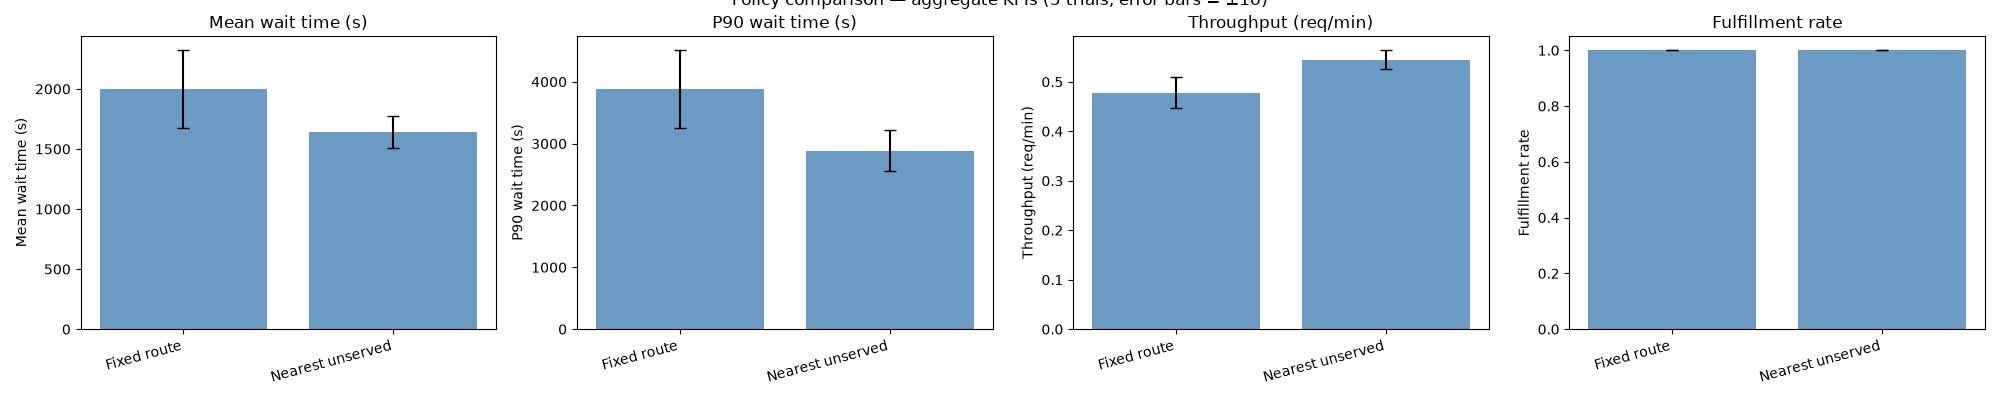

In [8]:
fig = plot_kpi_bars(
    results,
    fields=["mean_wait_time", "p90_wait_time", "throughput", "fulfillment_rate"],
)
fig.suptitle(
    f"Policy comparison — aggregate KPIs ({N_TRIALS} trials, error bars = ±1σ)",
    y=1.02,
)
# fig

## 5. Wait time distributions — `plot_wait_distribution`

`plot_kpi_bars` shows means and standard deviations, but those statistics can
hide a lot: a policy with a low mean might still have a heavy tail of very long
waits. `plot_wait_distribution` draws a box plot that reveals the full shape of
the distribution.

All trials for each policy are **pooled** before plotting, so with 5 trials of
100 requests each the box represents up to 500 individual wait-time samples.

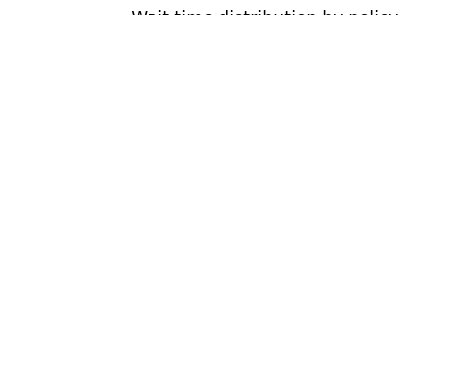

In [9]:
fig = plot_wait_distribution(results)
fig

## 6. Queue dynamics over time — `plot_occupancy`

`plot_occupancy` shows how **bus occupancy** (passengers currently on board) and
**pending request count** (passengers still waiting at stops) evolve over
simulation time.

Each policy gets one row of two subplots (occupancy / pending). When multiple
trials are available:
- Each individual trial is drawn as a **semi-transparent line**.
- The **per-tick mean** across all trials is overlaid as a solid line.

This is useful for diagnosing queue dynamics: a demand-responsive policy should
drain the pending queue faster, but may achieve higher occupancy at the cost of
longer wait times in some configurations.

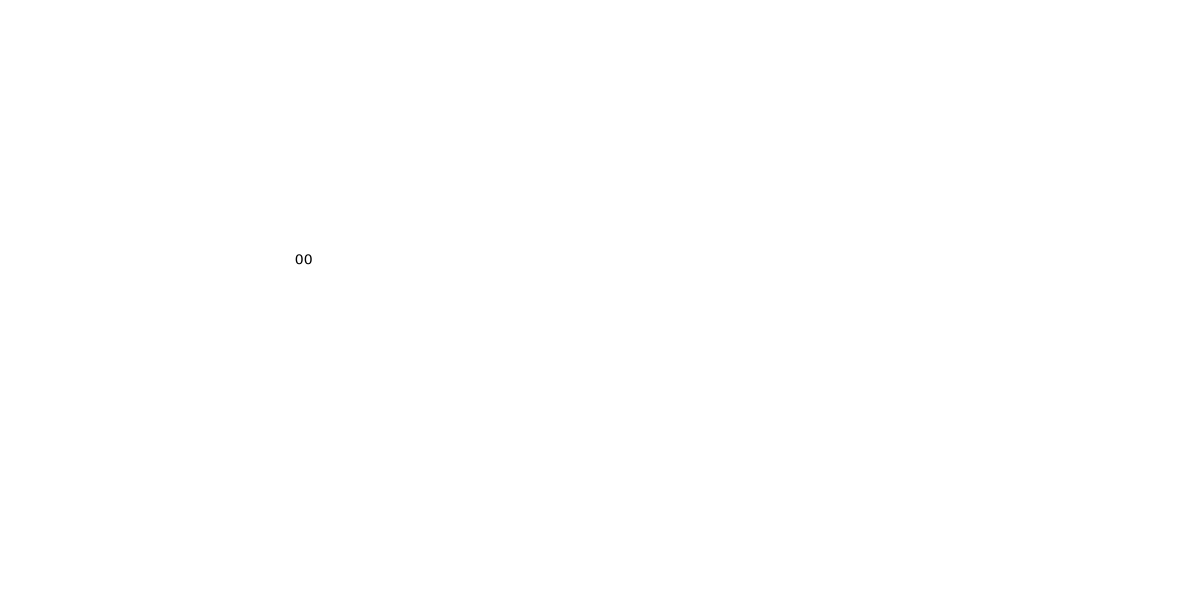

In [10]:
fig = plot_occupancy(results)
fig

## 7. Per-trial animation — `show_animation` / `show_animations`

The `compare_policies` run above didn't pass `record_animation=True`, so none
of the `TrialResult`s in `results` carry animation frames — capturing them
adds overhead we don't want in a 5-trial comparison, and frames are recorded
live during the run, so they can't be reconstructed afterwards.

To visualise a policy in action, we run **one fresh single trial per policy**
with `record_animation=True` — the same idiom from section 2, just with the
flag turned on. This switches the notebook to the `ipympl`
(`%matplotlib widget`) backend and displays an interactive, playable
animation of the bus serving requests stop by stop.

`show_animation(result)` displays a single trial. `show_animations(results)`
takes a `{label: TrialResult}` mapping and shows every trial side by side,
driven by one shared frame index — so the panels always play in lockstep at
the same speed, even if the two policies' runs recorded different numbers of
stop arrivals (a shorter panel simply freezes on its last frame once its
trial is done). Both display Pause/Resume and 0.5x/1x/2x speed buttons below
the animation.

In [ ]:
print("--- FixedRoutePolicy (recorded) ---")
fixed_anim_result = run_trial(
    policy_factory=lambda g: FixedRoutePolicy(g),
    graph=graph,
    seed=0,
    record_animation=True,
)

print("\n--- NearestUnservedPolicy (recorded) ---")
nearest_anim_result = run_trial(
    policy_factory=lambda g: NearestUnservedPolicy(g),
    graph=graph,
    seed=0,
    record_animation=True,
)

In [ ]:
show_animations({
    "Fixed route": fixed_anim_result,
    "Nearest unserved": nearest_anim_result,
})

## Summary

The charts above reveal the fundamental trade-off between the two policies:

- **`FixedRoutePolicy`** visits every stop on a predetermined cycle regardless of
  where passengers actually are. A passenger may wait a full cycle before the bus
  returns to their stop, leading to higher and more variable wait times. The route
  is predictable but inefficient for sparse or unevenly distributed demand.

- **`NearestUnservedPolicy`** always heads toward the nearest stop with an active
  need, so it reacts immediately to new requests. This typically reduces mean wait
  time, but the purely greedy strategy can make suboptimal decisions — for example,
  repeatedly detouring to nearby pickups while ignoring passengers already on board
  waiting for their dropoff.

---

### Next steps

The experiment package makes it easy to explore further. Some ideas:

```python
# How does capacity affect NearestUnserved?
results_low_cap = compare_policies(
    policies=[("Nearest unserved", lambda g: NearestUnservedPolicy(g))],
    graph=graph, n_trials=5, base_seed=0, capacity=4,
)

# How do both policies scale with more demand?
results_high_demand = compare_policies(
    policies=[
        ("Fixed route",      lambda g: FixedRoutePolicy(g)),
        ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
    ],
    graph=graph, n_trials=5, base_seed=0, max_requests=300,
)

# Plug in a new policy with no other changes:
results_new = compare_policies(
    policies=[("My new policy", lambda g: MyPolicy(g))],
    graph=graph, n_trials=5, base_seed=0,
)
```